# Company A: Customer Churn Analysis and Retention Proposal

**GCI World 2026 September · Final Assignment** · Abdulbari Al-Ameer

This notebook holds the full analysis behind my proposal slides. Running it from top to bottom reproduces every number and chart in the deck.

| Section | Content |
|---|---|
| 1 | Setup and data loading |
| 2 | Data quality check |
| 3 | Exploratory data analysis |
| 4 | Problem definition |
| 5 | Preprocessing and feature engineering |
| 6 | Modeling and evaluation |
| 7 | Market context and business proposal |
| 8 | Conclusion and references |

## 1. Setup and data loading
### 1.1 Libraries

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 200)

RANDOM_STATE = 42  # fixed seed so every number in the slides can be reproduced

# Consistent chart style for the whole notebook
sns.set_theme(style="whitegrid", context="notebook")
COLOR_STAY, COLOR_CHURN = "#2a78d6", "#eb6834"   # blue = stayed, orange = churned

### 1.2 Locate the data
The data files are not included in this repository (see `data/README.md`). The cell below looks for them in Google Drive (Colab), in `data/telecom/` of this repository, or in a `telecom/` folder next to the notebook.

In [2]:
# Works in three places: Google Colab (data in Drive), this repository (data/telecom), or the current folder.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

candidates = [Path("/content/drive/MyDrive/Final Assignment/telecom"),   # <-- Colab: edit if your folder differs
              Path("../data/telecom"), Path("data/telecom"), Path("telecom")]
DATA_DIR = next((p for p in candidates if (p / "Client.csv").exists()), candidates[0])

for f in ["Client.csv", "Record.csv"]:
    print(("OK      " if (DATA_DIR / f).exists() else "MISSING ") + f"telecom/{f}")

OK      telecom/Client.csv
OK      telecom/Record.csv


### 1.3 Load and merge the two tables
`Client.csv` has customer profile data (tenure, handset, household). `Record.csv` has usage, billing and call quality, plus the `churn` label. Both have one row per customer, so I join them on `Customer_ID` after checking that the IDs match.

In [3]:
client = pd.read_csv(DATA_DIR / "Client.csv")
record = pd.read_csv(DATA_DIR / "Record.csv")
print(f"Client: {client.shape}  |  Record: {record.shape}")

# Sanity checks before joining: IDs must be unique in both tables and fully overlapping
print("Unique IDs in Client:", client["Customer_ID"].is_unique)
print("Unique IDs in Record:", record["Customer_ID"].is_unique)
print("IDs in Record but not in Client:", (~record["Customer_ID"].isin(client["Customer_ID"])).sum())
print("Shared columns besides the key:", sorted(set(client.columns) & set(record.columns) - {"Customer_ID"}))

df = record.merge(client, on="Customer_ID", how="inner", validate="one_to_one")
print(f"Merged table: {df.shape[0]:,} customers x {df.shape[1]} columns")
df.head()

Client: (100000, 50)  |  Record: (100000, 51)
Unique IDs in Client: True
Unique IDs in Record: True
IDs in Record but not in Client: 0
Shared columns besides the key: []
Merged table: 100,000 customers x 100 columns


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,change_rev,drop_vce_Mean,drop_dat_Mean,blck_vce_Mean,blck_dat_Mean,unan_vce_Mean,unan_dat_Mean,plcd_vce_Mean,plcd_dat_Mean,recv_vce_Mean,recv_sms_Mean,comp_vce_Mean,comp_dat_Mean,custcare_Mean,ccrndmou_Mean,cc_mou_Mean,inonemin_Mean,threeway_Mean,mou_cvce_Mean,mou_cdat_Mean,mou_rvce_Mean,owylis_vce_Mean,mouowylisv_Mean,iwylis_vce_Mean,mouiwylisv_Mean,peak_vce_Mean,peak_dat_Mean,mou_peav_Mean,mou_pead_Mean,opk_vce_Mean,opk_dat_Mean,mou_opkv_Mean,mou_opkd_Mean,drop_blk_Mean,attempt_Mean,complete_Mean,callfwdv_Mean,callwait_Mean,churn,months,Customer_ID,uniqsubs,actvsubs,new_cell,crclscod,asl_flag,totcalls,totmou,totrev,adjrev,adjmou,adjqty,avgrev,avgmou,avgqty,avg3mou,avg3qty,avg3rev,avg6mou,avg6qty,avg6rev,prizm_social_one,area,dualband,refurb_new,hnd_price,phones,models,hnd_webcap,truck,rv,ownrent,lor,dwlltype,marital,adults,infobase,income,numbcars,HHstatin,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,-18.9975,0.666667,0.0,0.666667,0.0,6.333333,0.0,52.333333,0.0,42.333333,0.0,45.000000,0.0,0.000000,0.000000,0.000000,18.000000,0.000000,90.643333,0.0,97.176667,0.000000,0.000000,0.000000,0.000000,58.000000,0.0,132.600000,0.0,24.000000,0.0,55.220000,0.0,1.333333,52.333333,45.000000,0.0,0.333333,1,61,1000001,2,1,U,A,N,1652,4228.00000,1504.62,1453.44,4085.00,1602,29.66,83.37,32.69,272,116,30,322.0,136.0,38.0,S,NORTHWEST/ROCKY MOUNTAIN AREA,Y,N,149.98999,2.0,2.0,WCMB,0.0,0.0,O,15.0,S,S,1.0,M,4.0,3.0,C,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,50.9875,8.333333,0.0,1.000000,0.0,61.333333,0.0,263.333333,0.0,69.000000,0.0,193.333333,0.0,1.666667,6.333333,5.463333,53.000000,0.333333,189.396667,0.0,55.280000,46.333333,24.216667,6.333333,3.696667,83.666667,0.0,75.333333,0.0,157.000000,0.0,169.343333,0.0,9.333333,263.333333,193.333333,0.0,5.666667,0,56,1000002,1,1,N,EA,N,14654,26400.00000,2851.68,2833.88,26367.00,14624,51.53,479.40,265.89,305,158,40,477.0,275.0,48.0,U,CHICAGO AREA,N,N,NaN,7.0,6.0,WC,1.0,1.0,NaN,1.0,S,S,1.0,M,5.0,1.0,C,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,0.0000,0.333333,0.0,0.000000,0.0,2.666667,0.0,9.000000,0.0,0.333333,0.0,6.000000,0.0,0.000000,0.000000,0.000000,0.333333,0.000000,5.426667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,0.0,5.193333,0.0,1.000000,0.0,0.233333,0.0,0.333333,9.000000,6.000000,0.0,0.000000,1,58,1000003,1,1,Y,C,N,7903,24385.05333,2155.91,1934.47,24303.05,7888,34.54,433.98,140.86,12,7,17,11.0,6.0,17.0,S,GREAT LAKES AREA,N,N,29.98999,2.0,1.0,NaN,0.0,0.0,O,7.0,S,M,2.0,M,5.0,2.0,C,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,0.0000,0.000000,0.0,0.000000,0.0,0.000000,0.0,3.666667,0.0,1.333333,0.0,3.666667,0.0,0.000000,0.000000,0.000000,1.333333,0.000000,8.410000,0.0,0.413333,0.333333,0.256667,0.000000,0.000000,1.333333,0.0,3.380000,0.0,3.666667,0.0,5.450000,0.0,0.000000,3.666667,3.666667,0.0,0.000000,0,60,1000004,1,1,Y,B,N,1502,3065.00000,2000.90,1941.81,3035.00,1479,40.45,63.23,30.81,8,3,38,50.0,25.0,40.0,T,CHICAGO AREA,N,N,29.98999,1.0,1.0,NaN,0.0,0.0,NaN,6.0,M,M,4.0,M,6.0,1.0,C,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,0.0000,9.666667,0.0,0.666667,0.0,77.000000,0.0,222.333333,0.0,94.666667,0.0,137.000000,0.0,8.666667,15.000000,11.076667,66.000000,0.000000,285.233333,0.0,106.330000,14.666667,10.816667,0.666667,0.366667,97.333333,0.0,173.476667,0.0,90.333333,0.0,218.086667,0.0,10.333333,222.333333,137.000000,0.0,0.000000,0,57,1000005,1,1,Y,A,N,4485,14028.00000,2181.12,2166.48,13965.00,4452,38.69,249.38,79.50,558,191,55,586.0,196.0,80.0,U,NEW ENGLAND AREA,Y,N,149.98999,6.0,4.0,WCMB,0.0,0.0,R,5.0,M,S,1.0,M,6.0,1.0,C,O,0.0,I,U,U,U,U,U,Y,434.0


## 2. Data quality check
### 2.1 Column types

In [4]:
num_cols = df.select_dtypes(include="number").columns.drop(["churn", "Customer_ID"], errors="ignore").tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"Numeric columns:     {len(num_cols)}")
print(f"Categorical columns: {len(cat_cols)}")
print()
# How many distinct values each categorical column has (decides how we encode them later)
df[cat_cols].nunique(dropna=False).sort_values(ascending=False).to_frame("distinct values").T

Numeric columns:     77
Categorical columns: 21



,crclscod,area,ethnic,dwllsize,HHstatin,prizm_social_one,marital,dualband,hnd_webcap,infobase,new_cell,ownrent,refurb_new,kid6_10,dwlltype,kid0_2,kid3_5,kid16_17,kid11_15,creditcd,asl_flag
distinct values,54,20,18,16,7,6,6,5,4,3,3,3,3,3,3,3,3,3,3,3,2


### 2.2 Missing values
Which columns have gaps, and is a missing value linked to churn?

43 of 100 columns have missing values


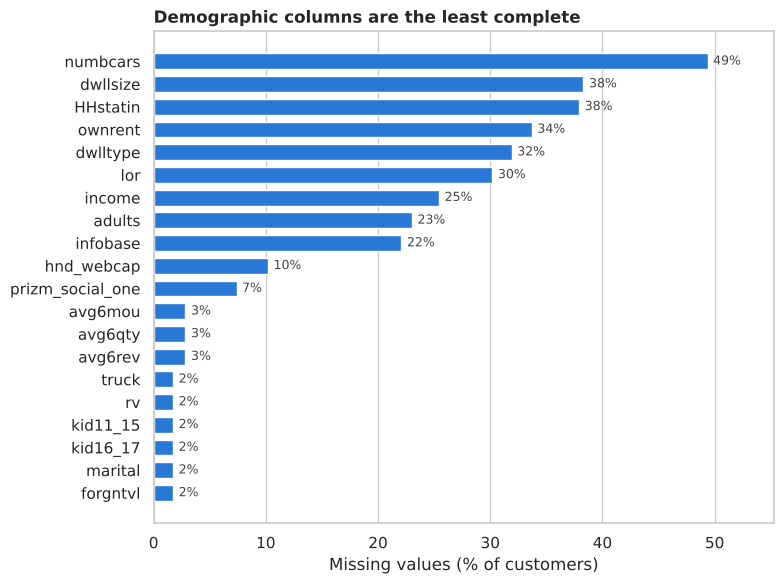

In [5]:
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]
print(f"{len(missing_pct)} of {df.shape[1]} columns have missing values")

top = missing_pct.head(20)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index[::-1], top.values[::-1], color=COLOR_STAY, height=0.7)
for y, v in enumerate(top.values[::-1]):
    ax.text(v + 0.5, y, f"{v:.0f}%", va="center", fontsize=9, color="#444")
ax.set_xlabel("Missing values (% of customers)")
ax.set_title("Demographic columns are the least complete", loc="left", fontweight="bold")
ax.set_xlim(0, max(top.values) * 1.12)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

In [6]:
# Is missingness itself related to churn? (a missing value can be a signal, not just noise)
rows = []
for col in missing_pct.index:
    is_na = df[col].isna()
    if is_na.sum() < 100:      # too few rows to say anything reliable
        continue
    rows.append({
        "column": col,
        "n missing": int(is_na.sum()),
        "missing %": round(is_na.mean() * 100, 1),
        "churn rate if missing": round(df.loc[is_na, "churn"].mean() * 100, 1),
        "churn rate if present": round(df.loc[~is_na, "churn"].mean() * 100, 1),
    })
miss_vs_churn = pd.DataFrame(rows)
miss_vs_churn["gap (pts)"] = miss_vs_churn["churn rate if missing"] - miss_vs_churn["churn rate if present"]
miss_vs_churn.sort_values("gap (pts)", key=abs, ascending=False).head(12)

,column,n missing,missing %,churn rate if missing,churn rate if present,gap (pts)
25,change_mou,891,0.9,76.1,49.3,26.8
26,change_rev,891,0.9,76.1,49.3,26.8
29,totmrc_Mean,357,0.4,68.6,49.5,19.1
30,ovrmou_Mean,357,0.4,68.6,49.5,19.1
33,vceovr_Mean,357,0.4,68.6,49.5,19.1
34,rev_Mean,357,0.4,68.6,49.5,19.1
28,da_Mean,357,0.4,68.6,49.5,19.1
35,mou_Mean,357,0.4,68.6,49.5,19.1
32,datovr_Mean,357,0.4,68.6,49.5,19.1
31,ovrrev_Mean,357,0.4,68.6,49.5,19.1


### 2.3 Target: `churn`
`churn` = 1 if the customer left 31–60 days after the observation date. The balance between the two classes decides which metrics make sense later.

         customers  share %
stayed       50438     50.4
churned      49562     49.6


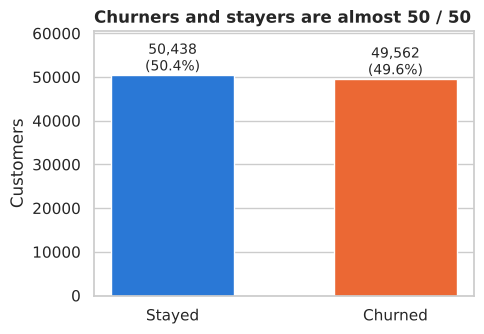

In [7]:
counts = df["churn"].value_counts().sort_index()
share = counts / counts.sum() * 100
print(pd.DataFrame({"customers": counts, "share %": share.round(1)}, index=[0, 1]).rename(index={0: "stayed", 1: "churned"}))

fig, ax = plt.subplots(figsize=(5, 3.5))
bars = ax.bar(["Stayed", "Churned"], counts.values, color=[COLOR_STAY, COLOR_CHURN], width=0.55)
for b, n, p in zip(bars, counts.values, share.values):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,}\n({p:.1f}%)", ha="center", va="bottom", fontsize=10)
ax.set_ylabel("Customers")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title("Churners and stayers are almost 50 / 50", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 2.4 Impossible values and outliers
A quick check of the main business columns for values that can't be right (such as negative revenue) and for extreme tails.

In [8]:
key_cols = ["rev_Mean", "mou_Mean", "totmrc_Mean", "ovrrev_Mean", "change_mou",
            "custcare_Mean", "drop_blk_Mean", "months", "eqpdays", "hnd_price"]
summary = df[key_cols].describe(percentiles=[0.01, 0.5, 0.99]).T
summary["negatives"] = (df[key_cols] < 0).sum()
summary["missing"] = df[key_cols].isna().sum()
summary.round(2)

,count,mean,std,min,1%,50%,99%,max,negatives,missing
rev_Mean,99643.0,58.72,46.29,-6.17,10.00,48.20,227.89,3843.26,5,357
mou_Mean,99643.0,513.56,525.17,0.00,0.00,355.50,2422.40,12206.75,0,357
totmrc_Mean,99643.0,46.18,23.62,-26.92,7.74,44.99,118.03,409.99,23,357
ovrrev_Mean,99643.0,13.56,30.50,0.00,0.00,1.00,139.27,1102.40,0,357
change_mou,99109.0,-13.93,276.09,-3875.00,-835.98,-6.25,751.46,31219.25,53651,891
custcare_Mean,100000.0,1.79,5.32,0.00,0.00,0.00,20.33,675.33,0,0
drop_blk_Mean,100000.0,10.04,15.42,0.00,0.00,5.33,70.67,489.67,0,0
months,100000.0,18.83,9.66,6.00,6.00,16.00,49.00,61.00,0,0
eqpdays,99999.0,391.93,256.48,-5.00,8.00,342.00,1165.00,1823.00,133,1
hnd_price,99153.0,101.88,61.01,9.99,9.99,99.99,199.99,499.99,0,847


In [9]:
print("Customers with negative monthly revenue:", (df["rev_Mean"] < 0).sum())
print("Customers with negative recurring charge:", (df["totmrc_Mean"] < 0).sum())
print("Customers with negative equipment age:  ", (df["eqpdays"] < 0).sum())
print("Customers with zero minutes of use:      ", (df["mou_Mean"] == 0).sum())
print("Duplicate rows (excluding ID):           ", df.drop(columns="Customer_ID").duplicated().sum())

Customers with negative monthly revenue: 5
Customers with negative recurring charge: 23
Customers with negative equipment age:   133
Customers with zero minutes of use:       1615


Duplicate rows (excluding ID):            0


### 2.5 What the data check showed
- **Clean join:** 100,000 customers × 100 columns, with no duplicates and no unmatched IDs. 77 columns are numeric and 21 are text.
- **Churn share in this file:** 49.6% of customers churned. The documentation does not say how the file was sampled. A real operator would not lose half its customers in two months, so the file may have been balanced on purpose, but I cannot confirm it. I use the data to *rank* customers by risk; the business case in Section 7 uses an assumed real-world churn rate instead.
- **Missing values carry information:** the ~357 customers with no usage averages churn at about 69%, and the ~891 with no `change_mou` at about 76%. Section 5 adds a flag for each of these two patterns. Other gaps are filled with the median (Logistic Regression, Random Forest) or left to LightGBM, which handles them natively. One check for a live system: these records must already be missing at the time of scoring, not filled in later.
- **Demographics are patchy:** `numbcars`, `dwllsize`, `HHstatin`, `ownrent` and `income` are 25–49% empty, so the proposal does not rely on them.
- **Negative values:** 133 negative handset ages, all between −1 and −5 days, are set to 0 in Section 5 (most likely a phone acquired around the observation date). The 23 negative monthly charges and 5 negative revenues are left as they are, since they may be billing credits.
- **Skewed numbers:** revenue and usage have long right tails (median revenue \$48, maximum \$3,843), so I mostly compare groups and medians rather than averages.
- **Currency:** the data dictionary does not state a currency. I show money with \$ for readability and keep every money value in the business case in these same units.

## 3. Exploratory data analysis

The question for this section: **what makes a customer who leaves different from one who stays?**

For each possible driver I compare the churn rate across groups with the overall 49.6%. I start with things the company can actually change (contract timing, handset, usage, service), because those are the ones a proposal can use.

### 3.0 Helper functions
Two small functions so every chart in this section works the same way: bars show the churn rate per group, the dashed line is the overall average, and orange marks the high-risk groups.

In [10]:
OVERALL_CHURN = df["churn"].mean()

def churn_by_group(groups, min_size=200):
    """Churn rate and customer count for each group (groups with too few customers are dropped)."""
    t = df.groupby(groups, observed=True)["churn"].agg(churn_rate="mean", customers="size")
    return t[t["customers"] >= min_size]

def plot_churn(table, title, xlabel, highlight_above=0.55, figsize=(9, 4), rotate=0):
    """Bar chart of churn rate per group; groups above `highlight_above` are drawn in orange."""
    rates = table["churn_rate"] * 100
    colors = [COLOR_CHURN if r >= highlight_above * 100 else COLOR_STAY for r in rates]
    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(table.index.astype(str), rates, color=colors, width=0.75)
    ax.axhline(OVERALL_CHURN * 100, ls="--", lw=1.2, color="#555")
    ax.text(len(rates) - 0.5, OVERALL_CHURN * 100 + 1, f"overall {OVERALL_CHURN:.1%}",
            ha="right", va="bottom", fontsize=9, color="#555")
    ax.set_ylabel("Churn rate (%)")
    ax.set_xlabel(xlabel)
    ax.set_ylim(0, max(rates.max() * 1.15, 60))
    ax.set_title(title, loc="left", fontweight="bold")
    ax.grid(axis="x", visible=False)
    plt.xticks(rotation=rotate)
    plt.tight_layout()
    plt.show()

### 3.1 Tenure
`months` is how long the customer has been with the company. Mobile contracts are often 12 months long, but the data does not say whether Company A uses contracts, so I simply look at churn month by month.

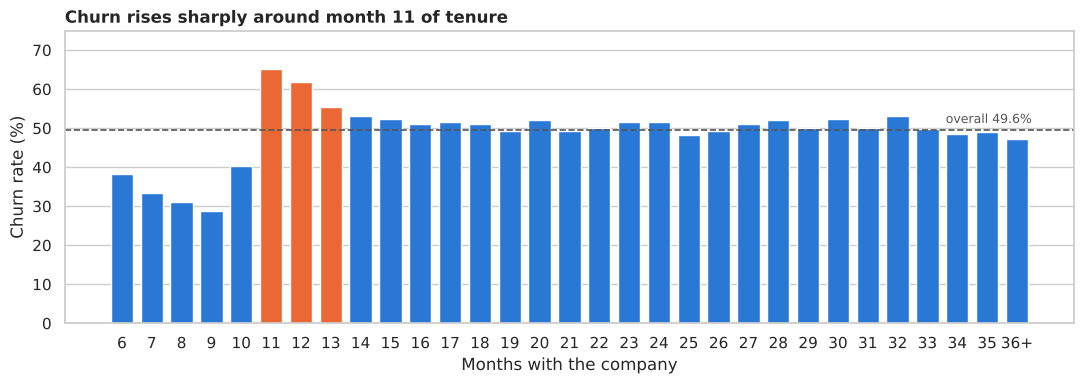

,churn_rate,customers
6,38.4%,"1,295"
7,33.3%,"4,979"
8,31.0%,"3,728"
9,28.8%,"4,066"
10,40.3%,"4,313"
11,65.1%,"8,029"
12,61.9%,"6,033"
13,55.4%,"5,651"
14,53.0%,"4,552"
15,52.4%,"3,835"


In [11]:
tenure = churn_by_group(df["months"].clip(upper=36))
tenure.index = [f"{m}" if m < 36 else "36+" for m in tenure.index]
plot_churn(tenure, "Churn rises sharply around month 11 of tenure",
           "Months with the company", highlight_above=0.55, figsize=(11, 4))
tenure.head(12).style.format({"churn_rate": "{:.1%}", "customers": "{:,}"})

**Result**
- Months 7–10: churn is low, between 29% and 40%. Customers are still on their first contract.
- Month 11: churn jumps to about 65%, the highest point in the whole customer lifetime, and stays above average until month 14.
- After that it settles around 50%.

**My reading (a hypothesis, not proven):** `churn` counts customers who leave 31–60 days after the observation date, so a customer observed in month 11 is deciding in month 12 or 13. That fits the end of a 12-month contract, although the data does not record contract dates. If this is right, any action should come before the peak, in months 9–10.

### 3.2 Handset age
`eqpdays` is the age of the customer's current phone in days. I convert it to months.

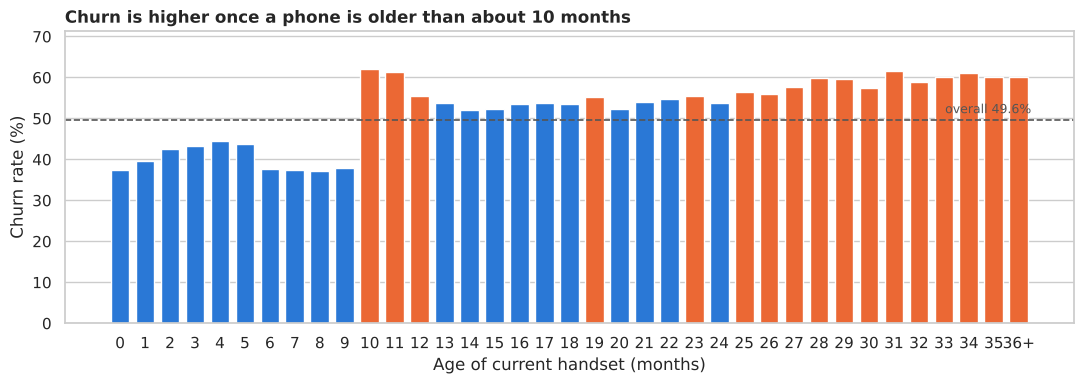

In [12]:
eq_months = np.floor(df["eqpdays"].clip(lower=0) / 30.4).clip(upper=36)   # one customer has no value -> left out
eq = churn_by_group(eq_months)
eq.index = [f"{int(m)}" if m < 36 else "36+" for m in eq.index]
plot_churn(eq, "Churn is higher once a phone is older than about 10 months",
           "Age of current handset (months)", highlight_above=0.55, figsize=(11, 4))

**Result**
- Phones under 10 months old: churn of 37–44%, below average.
- From 10 months on: churn jumps to about 60% and stays above average for older phones.

**My reading (a hypothesis):** if phones are often bought together with a contract, phone age and tenure would rise together. A customer whose contract is ending and whose phone is getting old may have two reasons to look at other operators. The data shows the association, not the cause.

### 3.3 Tenure and handset age together
Because these two move together, I look at them side by side. Holding tenure fixed shows whether phone age matters on its own.

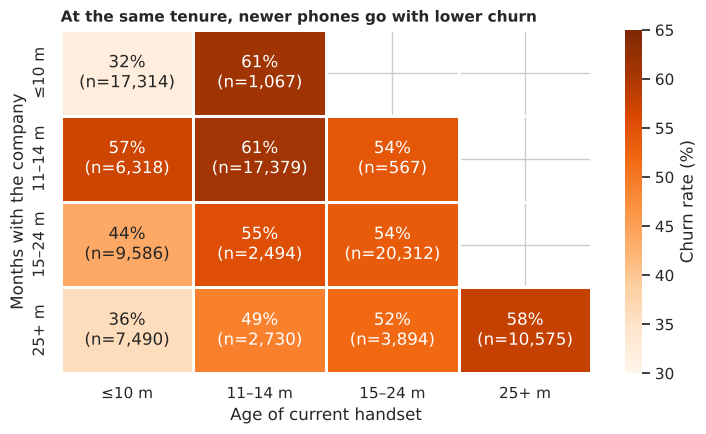

In [13]:
tenure_band = pd.cut(df["months"], [0, 10, 14, 24, 61],
                     labels=["≤10 m", "11–14 m", "15–24 m", "25+ m"])
eq_band = pd.cut(df["eqpdays"].clip(lower=0) / 30.4, [-0.1, 10, 14, 24, 100],
                 labels=["≤10 m", "11–14 m", "15–24 m", "25+ m"])

rate = df.pivot_table(index=tenure_band, columns=eq_band, values="churn", aggfunc="mean", observed=False)
size = df.pivot_table(index=tenure_band, columns=eq_band, values="churn", aggfunc="size", observed=False)
rate = rate.where(size >= 500)              # hide cells with too few customers to trust

annot = rate.map(lambda v: "" if pd.isna(v) else f"{v:.0%}") + size.where(rate.notna()).map(
        lambda n: "" if pd.isna(n) else f"\n(n={int(n):,})")

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(rate * 100, annot=annot, fmt="", cmap="Oranges", vmin=30, vmax=65,
            linewidths=2, linecolor="white", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_xlabel("Age of current handset")
ax.set_ylabel("Months with the company")
ax.set_title("At the same tenure, newer phones go with lower churn",
             loc="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

**Result** (read each row: same tenure, different phone age)
- 25+ months with the company: 36% churn with a phone up to 10 months old, 58% with a phone over 2 years old.
- 15–24 months: 44% with a recent phone, 54–55% with an older one.
- 11–14 months (contract end): 54–61%, whatever the phone age.

**Why it matters:** the company cannot change a customer's tenure, but it can offer a new phone, and customers with a recent handset churn much less even at the same tenure. This is a correlation, not proof: loyal customers may simply be the ones who upgrade. A pilot with a control group is needed to test it.

### 3.4 Handset price and type

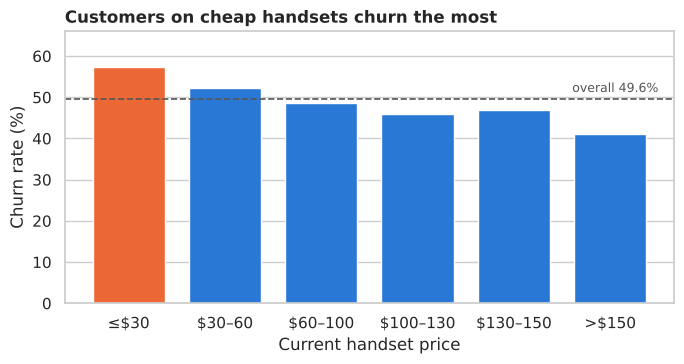

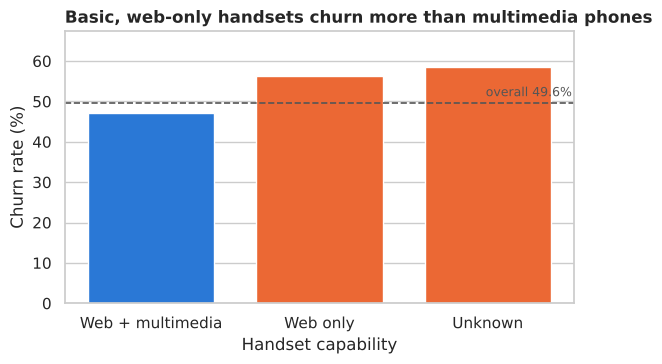

In [14]:
price = churn_by_group(pd.cut(df["hnd_price"], [0, 30, 60, 100, 130, 150, 500],
                              labels=["≤$30", "$30–60", "$60–100", "$100–130", "$130–150", ">$150"]))
plot_churn(price, "Customers on cheap handsets churn the most", "Current handset price",
           highlight_above=0.55, figsize=(7, 3.8))

webcap = df["hnd_webcap"].fillna("Unknown").replace({"WCMB": "Web + multimedia", "WC": "Web only",
                                                     "UNKW": "Unknown"})
plot_churn(churn_by_group(webcap).sort_values("churn_rate"),
           "Basic, web-only handsets churn more than multimedia phones", "Handset capability",
           highlight_above=0.55, figsize=(6, 3.8))

**Result:** churn falls as the handset price rises, from about 57% for phones at \$30 or less to 41% above \$150. Basic web-only phones churn more than multimedia phones (about 56% vs 47%). Customers on cheap or basic devices are the easiest for a competitor's phone deal to win over.

### 3.5 Usage
`change_mou` compares this month's minutes with the previous three-month average. The data dictionary calls it a percentage, but its values run from −3,875 to +31,219, which looks more like a difference in minutes. I treat it that way.

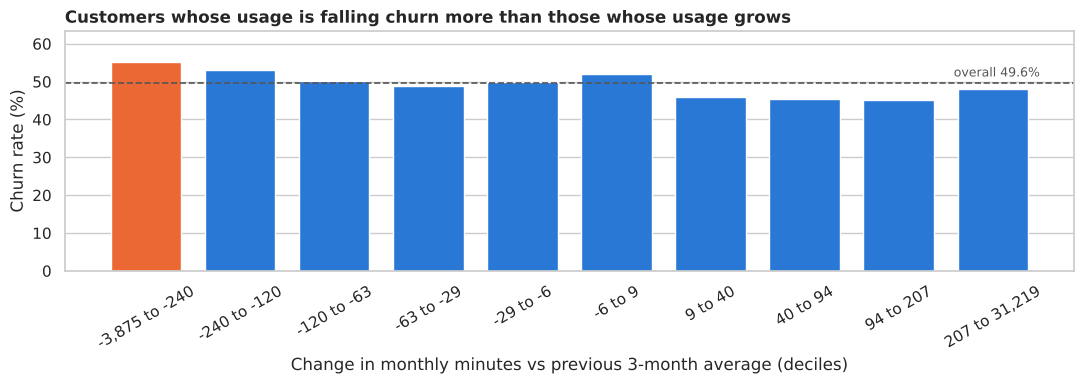

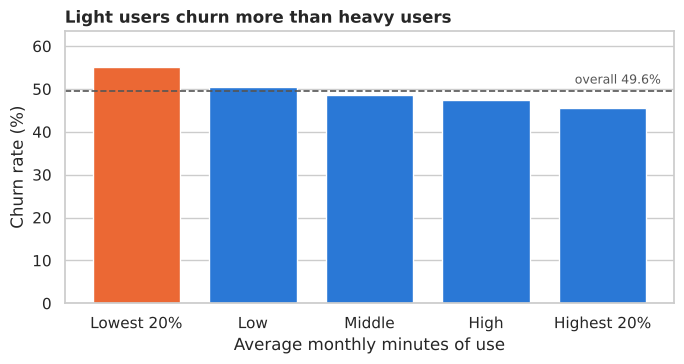

In [15]:
usage_trend = churn_by_group(pd.qcut(df["change_mou"], 10))
usage_trend.index = [f"{iv.left:,.0f} to {iv.right:,.0f}" for iv in usage_trend.index]
plot_churn(usage_trend, "Customers whose usage is falling churn more than those whose usage grows",
           "Change in monthly minutes vs previous 3-month average (deciles)",
           highlight_above=0.53, figsize=(11, 4), rotate=30)

usage_level = churn_by_group(pd.qcut(df["mou_Mean"], 5, labels=["Lowest 20%", "Low", "Middle", "High", "Highest 20%"]))
plot_churn(usage_level, "Light users churn more than heavy users", "Average monthly minutes of use",
           highlight_above=0.53, figsize=(7, 3.8))

**Result:** customers whose minutes fell by more than about 120 churn at 53–55%, against 45–46% for those whose usage grew. The lightest users churn more than the heaviest (about 55% vs 46%). This is a real signal, but weaker than contract timing and phone age, so I use it as an early warning rather than the main story.

### 3.6 Service quality and customer care

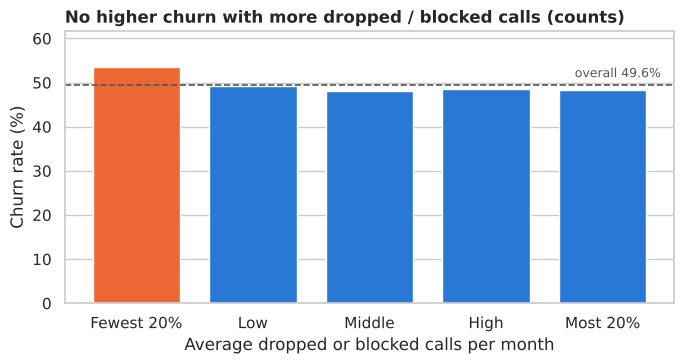

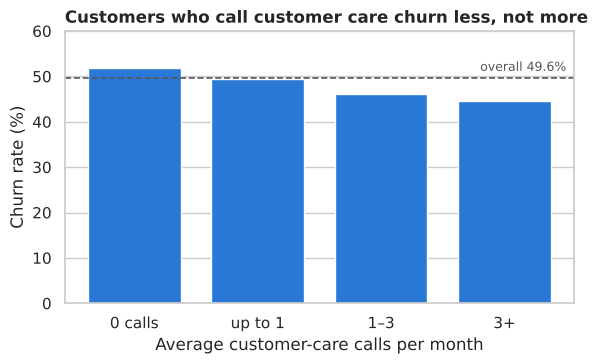

In [16]:
drops = churn_by_group(pd.qcut(df["drop_blk_Mean"].rank(method="first"), 5,
                               labels=["Fewest 20%", "Low", "Middle", "High", "Most 20%"]))
plot_churn(drops, "No higher churn with more dropped / blocked calls (counts)",
           "Average dropped or blocked calls per month", highlight_above=0.53, figsize=(7, 3.8))

care = churn_by_group(pd.cut(df["custcare_Mean"], [-0.1, 0, 1, 3, 1000],
                             labels=["0 calls", "up to 1", "1–3", "3+"]))
plot_churn(care, "Customers who call customer care churn less, not more",
           "Average customer-care calls per month", highlight_above=0.53, figsize=(6, 3.8))

**Result (not what I expected)**
- More dropped or blocked calls do not come with more churn. The group with the fewest drops actually churns slightly more.
- Customers who never call customer care churn more (about 52%) than those who call three or more times a month (about 45%).

**My reading:** both measures rise with usage. Heavy users make more calls, so they see more drops and contact support more often, and heavy users tend to stay. These columns are *counts*, not drop *rates*, so they may not measure network quality well. I therefore do not conclude that the network is unimportant, only that this data gives no sign that it drives churn, so it is not where I focus the proposal.

### 3.7 Overlapping columns
Several columns measure nearly the same thing (this month's revenue, the 3-month average, the 6-month average, the lifetime total). I check how closely they move together.

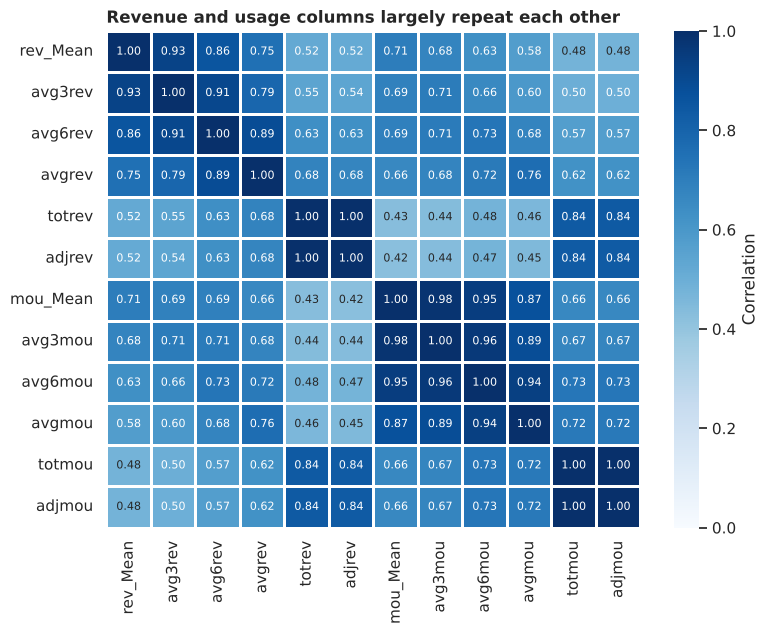

,,correlation
totmou,adjmou,0.999747
totrev,adjrev,0.998492
mou_Mean,avg3mou,0.981123
avg3mou,avg6mou,0.962436


,kept,dropped,correlation,share exactly equal
0,totrev,adjrev,0.9985,0.0064
1,totmou,adjmou,0.9997,0.1488
2,totcalls,adjqty,0.9998,0.1487


In [17]:
rev_mou_cols = ["rev_Mean", "avg3rev", "avg6rev", "avgrev", "totrev", "adjrev",
                "mou_Mean", "avg3mou", "avg6mou", "avgmou", "totmou", "adjmou"]
corr = df[rev_mou_cols].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8},
            linewidths=1, linecolor="white", cbar_kws={"label": "Correlation"}, ax=ax)
ax.set_title("Revenue and usage columns largely repeat each other", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

# List the near-duplicate pairs (correlation above 0.95)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
             .loc[lambda s: s > 0.95].sort_values(ascending=False))
display(pairs.to_frame("correlation"))

# The three billing-adjusted columns dropped later: how close are they to the unadjusted ones?
check = []
for raw, adj in [("totrev", "adjrev"), ("totmou", "adjmou"), ("totcalls", "adjqty")]:
    both = df[[raw, adj]].dropna()
    check.append({"kept": raw, "dropped": adj, "correlation": both[raw].corr(both[adj]),
                  "share exactly equal": np.isclose(both[raw], both[adj]).mean()})
pd.DataFrame(check).round(4)

**Result:** the billing-adjusted columns are almost, but not exactly, the same as the unadjusted ones: `totrev`/`adjrev`, `totmou`/`adjmou` and `totcalls`/`adjqty` all have a correlation of 0.998 or higher, although the values are rarely identical. The different usage averages are also strongly linked (0.86–0.98). Since each adjusted column adds almost no new information, I keep the unadjusted version and drop `adjrev`, `adjmou` and `adjqty` before modeling.

### 3.8 Summary of the analysis

| # | Finding | Churn rate | Can the company act on it? |
|---|---|---|---|
| 1 | Churn peaks when the first contract ends (month 11) | ~65% vs 29% in month 9 | Yes: timing of offers |
| 2 | Phones older than 10 months | ~60% vs ~38% | Yes: upgrade offers |
| 3 | Long-standing customers with a recent phone | 36% vs 58% with an old phone | Yes: supports finding 2 |
| 4 | Cheap or basic handsets | ~57% at ≤\$30 vs 41% above \$150 | Partly: upgrade to a better device |
| 5 | Falling or low usage | ~55% vs ~46% | Yes: early warning |
| 6 | Missing usage records | 69–76% | Yes: alert, if the gap is visible at scoring time |
| 7 | Dropped calls and care calls | no increase | No sign in this data; not the focus of the proposal |

**Working hypothesis**
> Churn is highest around month 11 of tenure and among customers whose phone is older than 10 months. These are associations, not proven causes. If they reflect contract end and phone ageing, then spotting these customers before month 11 and offering a new phone with a renewal could keep more of them for less money than a broad campaign. This is a hypothesis to test, not a conclusion.

The next sections test this with a predictive model and put a value on it.

## 4. Problem definition

**Business question**
> Which customers are likely to leave in the next one to two months, so the company can make them the right offer before they decide?

| Item | Choice | Reason |
|---|---|---|
| Target | `churn` | It measures the loss directly, and Section 3 found clear drivers the company can act on. |
| Task | Binary classification with a risk score | The retention team needs a ranked list, not just a yes or no. |
| Main metric | ROC-AUC | It measures how well the model ranks leavers above stayers, which is how the list will be used. |
| Other metrics | Accuracy, precision, recall, F1, churners caught in the top 10–30% | Accuracy is meaningful here because the classes are balanced; the top-X% figures show campaign size and cost. |
| Who uses it | Retention team | Each month: score all customers and contact the riskiest group. |

## 5. Preprocessing and feature engineering

Each step below follows from something found in Sections 2 and 3.

| What I found | What I did |
|---|---|
| `Customer_ID` is only an identifier | Dropped |
| 133 negative handset ages, all −1 to −5 days | Set to 0 (most likely a phone acquired around the observation date) |
| Missing usage records go with high churn | Added missing-value flags |
| `adjrev`, `adjmou`, `adjqty` nearly repeat the unadjusted columns (correlation ≥ 0.998) | Dropped |
| 28 negative revenues / monthly charges | Kept as they are (possible billing credits) |
| Churn jumps at months 10–14 of tenure and at 10 months of phone age | Added simple features for both |
| Usage change and overage depend on the customer's usual level | Added two ratios; +1 in each denominator avoids dividing by zero |
| `ethnic` (ethnicity code) | Left out on purpose: offers should never depend on ethnicity, and the company cannot act on it |
| Other text columns | Encoded (one-hot, or native categories for LightGBM) |

Section 6.4b checks whether the added features actually help.

In [18]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve)
from lightgbm import LGBMClassifier

data = df.copy()

# --- Cleaning ---
# 133 customers have a negative handset age, all between -1 and -5 days. A phone cannot be "minus 5 days" old;
# the most plausible reading is a phone acquired around the observation date (a small date offset), so these are set to 0.
print("Negative handset ages:", (data["eqpdays"] < 0).sum(), "| range:", data.loc[data["eqpdays"] < 0, "eqpdays"].agg(["min", "max"]).tolist())
data["eqpdays"] = data["eqpdays"].clip(lower=0)
# Negative revenue (5) and monthly charge (23) values are left as they are: they may be billing credits or adjustments.
data = data.drop(columns=["Customer_ID", "adjrev", "adjmou", "adjqty"])   # billing-adjusted copies (corr >= 0.998, Section 3.7)
# Ethnicity is excluded on purpose: targeting offers by ethnicity is not acceptable, and it is not something the company can act on
data = data.drop(columns=["ethnic"])

# --- Missing-value flags (missingness itself predicts churn, Section 2.2) ---
data["usage_missing"]  = data["rev_Mean"].isna().astype(int)
data["change_missing"] = data["change_mou"].isna().astype(int)

# --- Business features from the EDA (Section 3) ---
data["eq_months"]           = data["eqpdays"] / 30.4                          # handset age in months
data["handset_older_10m"]   = (data["eq_months"] >= 10).astype(int)           # past the 10-month jump
data["contract_end_window"] = data["months"].between(10, 14).astype(int)      # months 10-14 = contract-end risk zone
data["eq_to_tenure"]        = data["eq_months"] / data["months"]              # ~1 = still on the original handset
# Ratios: +1 in the denominator avoids dividing by zero for customers with no usage / no revenue.
# change_mou is read as a difference in minutes (Section 3.5), so this is "change relative to the usual level";
# its exact unit is not confirmed by the data dictionary.
data["usage_change_ratio"]  = data["change_mou"] / (data["avg3mou"] + 1)
data["overage_share"]       = data["ovrrev_Mean"] / (data["rev_Mean"].clip(lower=0) + 1)  # negative revenue treated as 0 here only

X = data.drop(columns="churn")
y = data["churn"]
cat_features = X.select_dtypes(exclude="number").columns.tolist()
num_features = X.select_dtypes(include="number").columns.tolist()
print(f"Features: {X.shape[1]}  ({len(num_features)} numeric, {len(cat_features)} categorical)")

import sklearn, lightgbm, matplotlib
print(f"Versions: pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__} | "
      f"lightgbm {lightgbm.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

Negative handset ages: 133 | range: [-5.0, -1.0]
Features: 102  (82 numeric, 20 categorical)
Versions: pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1 | lightgbm 4.7.0 | matplotlib 3.11.2 | seaborn 0.13.2


### 5.1 Train / test split
I train on 70% of customers and keep 30% aside as a test set that the models do not see until the final evaluation. `stratify=y` keeps the churn share the same in both parts.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print(f"Train: {len(X_train):,} customers  |  Test: {len(X_test):,} customers")
print(f"Churn share  train {y_train.mean():.1%}  |  test {y_test.mean():.1%}")

Train: 70,000 customers  |  Test: 30,000 customers
Churn share  train 49.6%  |  test 49.6%


### 5.2 Encoding
- **Logistic Regression and Random Forest:** missing numbers are filled with the median; text columns are one-hot encoded, with missing values as their own category and rare credit codes grouped together. Logistic Regression also needs the inputs on the same scale.
- **LightGBM:** handles missing values and text categories by itself, so it gets the data almost as it is. The list of categories is taken from the training data only.

The imputers and encoders sit inside each pipeline, so in cross-validation they are fitted on the training folds only.

In [20]:
def make_preprocessor(scale):
    numeric = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale else [])
    categorical = [("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                   ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200,
                                            sparse_output=False))]
    return ColumnTransformer([("num", Pipeline(numeric), num_features),
                              ("cat", Pipeline(categorical), cat_features)])

# LightGBM: convert text columns to pandas 'category'. The list of categories is learned from the
# TRAINING data only; a value that appears only in the test data becomes missing (NaN).
TRAIN_CATEGORIES = {c: sorted(X_train[c].dropna().unique()) for c in cat_features}
def to_category(frame):
    frame = frame.copy()
    for c in cat_features:
        known = frame[c].where(frame[c].isin(TRAIN_CATEGORIES[c]))          # unseen values -> NaN
        frame[c] = pd.Categorical(known, categories=TRAIN_CATEGORIES[c])
    return frame

X_train_lgb, X_test_lgb = to_category(X_train), to_category(X_test)

## 6. Modeling and evaluation

I compare three models, from simple to flexible:

| Model | Why |
|---|---|
| Baseline (always "stay") | A model that ignores the data; anything useful must beat it. |
| Logistic Regression | Simple, transparent linear model. |
| Random Forest | Many decision trees voting together; picks up combinations such as tenure × phone age. |
| LightGBM | Gradient boosting: trees built one after another, each correcting the previous one. Usually the strongest option for table data. |

### 6.1 Cross-validation
Each model is trained and scored five times on different parts of the training data, so the comparison does not depend on one lucky split. The ± figure is the standard deviation across the five folds, not a confidence interval.

**The model is chosen on these cross-validation scores.** The test set is used only afterwards, once, to report how the chosen model performs.

In [21]:
from sklearn.dummy import DummyClassifier

models = {
    "Baseline (always 'stay')": DummyClassifier(strategy="prior"),
    "Logistic Regression": Pipeline([("prep", make_preprocessor(scale=True)),
                                     ("model", LogisticRegression(max_iter=2000, C=0.5))]),
    "Random Forest":       Pipeline([("prep", make_preprocessor(scale=False)),
                                     ("model", RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                                      max_features="sqrt", n_jobs=-1,
                                                                      random_state=RANDOM_STATE))]),
    "LightGBM":            LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=63,
                                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                                          colsample_bytree=0.7, random_state=RANDOM_STATE, verbose=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, model in models.items():
    Xtr = X_train_lgb if name == "LightGBM" else X_train
    scores = cross_val_score(model, Xtr, y_train, cv=cv, scoring="roc_auc", n_jobs=1)
    cv_results[name] = scores
    print(f"{name:<26} ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}   (mean ± standard deviation over 5 folds)")

# The model is chosen HERE, on cross-validation scores from the training data - before the test set is used
best_name = max((n for n in cv_results if not n.startswith("Baseline")), key=lambda n: cv_results[n].mean())
print(f"\nChosen on cross-validation: {best_name}")

Baseline (always 'stay')   ROC-AUC = 0.5000 ± 0.0000   (mean ± standard deviation over 5 folds)


Logistic Regression        ROC-AUC = 0.6545 ± 0.0029   (mean ± standard deviation over 5 folds)


Random Forest              ROC-AUC = 0.6817 ± 0.0009   (mean ± standard deviation over 5 folds)


LightGBM                   ROC-AUC = 0.6977 ± 0.0023   (mean ± standard deviation over 5 folds)

Chosen on cross-validation: LightGBM


### 6.2 Final test on unseen customers
Accuracy, precision, recall and F1 use a 0.5 cut-off for evaluation only; the cut-off used for the business case is set in Section 7.4.

In [22]:
results, probas = [], {}
for name, model in models.items():
    Xtr, Xte = (X_train_lgb, X_test_lgb) if name == "LightGBM" else (X_train, X_test)
    model.fit(Xtr, y_train)
    p = model.predict_proba(Xte)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    results.append({"Model": name,
                    "ROC-AUC": roc_auc_score(y_test, p),
                    "Accuracy": accuracy_score(y_test, pred),
                    "Precision": precision_score(y_test, pred, zero_division=0),
                    "Recall": recall_score(y_test, pred),
                    "F1": f1_score(y_test, pred)})

# Test-set scores of every model, reported once (the choice was already made on cross-validation).
# Accuracy, precision, recall and F1 use a 0.5 cut-off for evaluation only; the business cut-off is set in Section 7.4.
results = pd.DataFrame(results).set_index("Model")
results.index = [f"{n} (chosen)" if n == best_name else n for n in results.index]
results.style.format("{:.3f}")

,ROC-AUC,Accuracy,Precision,Recall,F1
Baseline (always 'stay'),0.500,0.504,0.000,0.000,0.000
Logistic Regression,0.654,0.611,0.600,0.644,0.621
Random Forest,0.682,0.625,0.617,0.645,0.630
LightGBM (chosen),0.699,0.640,0.635,0.643,0.639


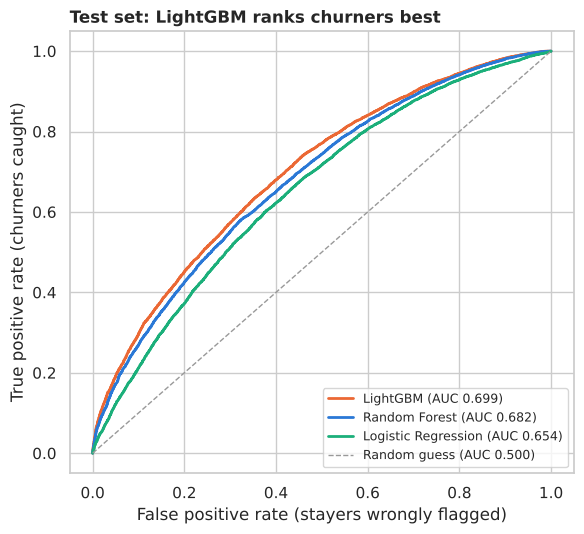

In [23]:
fig, ax = plt.subplots(figsize=(6, 5.5))
palette = {"LightGBM": COLOR_CHURN, "Random Forest": COLOR_STAY, "Logistic Regression": "#1baf7a"}
for name in palette:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    ax.plot(fpr, tpr, color=palette[name], lw=2, label=f"{name} (AUC {roc_auc_score(y_test, probas[name]):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="#999", lw=1, label="Random guess (AUC 0.500)")
ax.set_title("Test set: LightGBM ranks churners best", loc="left", fontweight="bold")
ax.set_xlabel("False positive rate (stayers wrongly flagged)")
ax.set_ylabel("True positive rate (churners caught)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

### 6.3 Where the model goes wrong

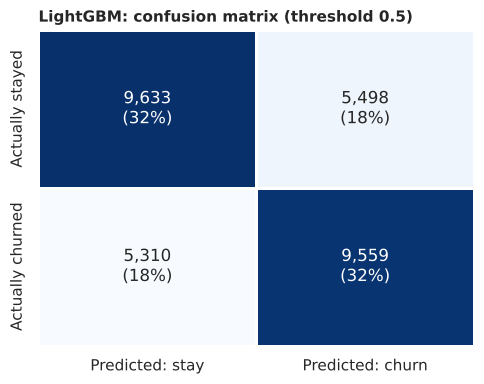

In [24]:
best_model = models[best_name]
best_proba = probas[best_name]
cm = confusion_matrix(y_test, (best_proba >= 0.5).astype(int))

fig, ax = plt.subplots(figsize=(5, 4))
labels = np.array([[f"{v:,}\n({v / cm.sum():.0%})" for v in row] for row in cm])
sns.heatmap(cm, annot=labels, fmt="", cmap="Blues", cbar=False, linewidths=2, linecolor="white",
            xticklabels=["Predicted: stay", "Predicted: churn"],
            yticklabels=["Actually stayed", "Actually churned"], ax=ax)
ax.set_title(f"{best_name}: confusion matrix (threshold 0.5)", loc="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

### 6.4 What drives the predictions
For each group of related inputs, I shuffle their values at random and measure how much the model's ROC-AUC drops. A bigger drop means the model relies more on that information. This measures predictive reliance, not cause and effect.

I shuffle whole groups because many columns overlap: shuffling only `eqpdays` would understate phone age, since the model could still read it from `eq_months`. Every input belongs to exactly one group; inputs not in a named group go into "Other call & data activity".

Groups cover all 102 features (23 in 'Other call & data activity')


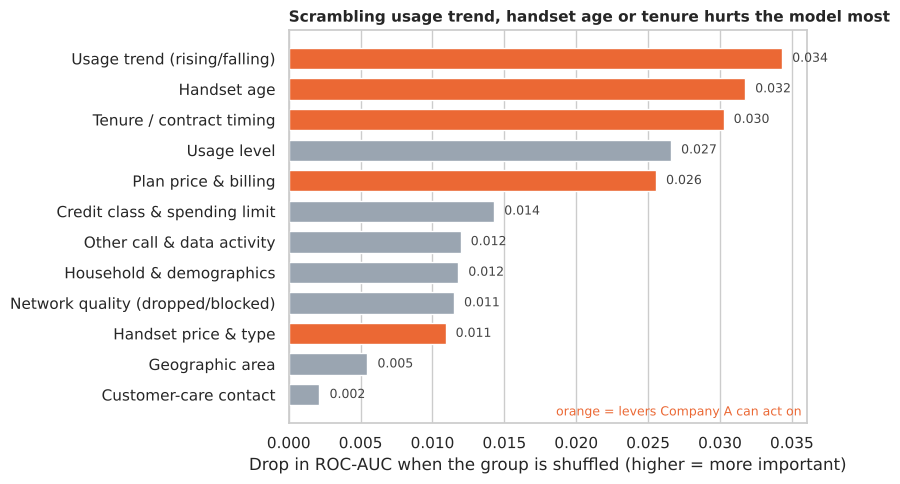

Baseline ROC-AUC on the 10,000-customer sample: 0.697


,AUC drop
Usage trend (rising/falling),0.0343
Handset age,0.0317
Tenure / contract timing,0.0303
Usage level,0.0266
Plan price & billing,0.0255
Credit class & spending limit,0.0143
Other call & data activity,0.0120
Household & demographics,0.0118
Network quality (dropped/blocked),0.0115
Handset price & type,0.0109


In [25]:
feature_groups = {
    "Handset age":                ["eqpdays", "eq_months", "handset_older_10m", "eq_to_tenure"],
    "Tenure / contract timing":   ["months", "contract_end_window"],
    "Usage trend (rising/falling)": ["change_mou", "change_rev", "usage_change_ratio", "change_missing"],
    "Usage level":                ["mou_Mean", "avg3mou", "avg6mou", "avgmou", "avgqty", "avg3qty", "avg6qty",
                                   "totcalls", "totmou", "plcd_vce_Mean", "comp_vce_Mean", "attempt_Mean",
                                   "complete_Mean", "peak_vce_Mean", "opk_vce_Mean", "recv_vce_Mean", "inonemin_Mean"],
    "Plan price & billing":       ["totmrc_Mean", "rev_Mean", "avgrev", "avg3rev", "avg6rev", "totrev",
                                   "ovrrev_Mean", "ovrmou_Mean", "vceovr_Mean", "overage_share", "usage_missing"],
    "Handset price & type":       ["hnd_price", "hnd_webcap", "refurb_new", "phones", "models", "dualband"],
    "Credit class & spending limit": ["crclscod", "asl_flag"],
    "Geographic area":            ["area"],
    "Household & demographics":   ["uniqsubs", "actvsubs", "lor", "income", "adults", "marital", "ownrent",
                                   "dwlltype", "dwllsize", "HHstatin", "numbcars", "infobase", "prizm_social_one",
                                   "forgntvl", "truck", "rv", "creditcd", "kid0_2", "kid3_5", "kid6_10",
                                   "kid11_15", "kid16_17", "new_cell"],
    "Network quality (dropped/blocked)": ["drop_vce_Mean", "drop_dat_Mean", "blck_vce_Mean", "blck_dat_Mean",
                                          "drop_blk_Mean", "unan_vce_Mean"],
    "Customer-care contact":      ["custcare_Mean", "ccrndmou_Mean", "cc_mou_Mean"],
}
# Every remaining input goes into one last group, so the analysis covers all features
covered = {c for cols in feature_groups.values() for c in cols}
feature_groups["Other call & data activity"] = [c for c in X.columns if c not in covered]
assert set().union(*feature_groups.values()) >= set(X.columns), "every feature must be in a group"
print(f"Groups cover all {len(X.columns)} features ({len(feature_groups['Other call & data activity'])} in 'Other call & data activity')")

lgb_model = models["LightGBM"]
sample = X_test_lgb.sample(10_000, random_state=RANDOM_STATE)
y_sample = y_test.loc[sample.index]
base_auc = roc_auc_score(y_sample, lgb_model.predict_proba(sample)[:, 1])
rng = np.random.default_rng(RANDOM_STATE)

drops = {}
for group, cols in feature_groups.items():
    cols = [c for c in cols if c in sample.columns]
    losses = []
    for _ in range(3):                                   # repeat 3 times and average
        shuffled = sample.copy()
        order = rng.permutation(len(shuffled))
        for c in cols:                                   # same order for every column = shuffle the group together
            shuffled[c] = shuffled[c].iloc[order].set_axis(shuffled.index)   # keeps the category dtype
        losses.append(base_auc - roc_auc_score(y_sample, lgb_model.predict_proba(shuffled)[:, 1]))
    drops[group] = np.mean(losses)

importance = pd.Series(drops).sort_values(ascending=False)
actionable = {"Handset age", "Tenure / contract timing", "Usage trend (rising/falling)",
              "Plan price & billing", "Handset price & type"}

fig, ax = plt.subplots(figsize=(8.5, 5))
colors = [COLOR_CHURN if g in actionable else "#9aa5b1" for g in importance.index]
ax.barh(importance.index[::-1], importance.values[::-1], color=colors[::-1], height=0.7)
for yv, v in enumerate(importance.values[::-1]):
    ax.text(v + 0.0007, yv, f"{v:.3f}", va="center", fontsize=9, color="#444")
ax.set_xlabel("Drop in ROC-AUC when the group is shuffled (higher = more important)")
ax.set_title("Scrambling usage trend, handset age or tenure hurts the model most",
             loc="left", fontweight="bold", fontsize=11)
ax.text(0.99, 0.02, "orange = levers Company A can act on", transform=ax.transAxes,
        ha="right", fontsize=9, color=COLOR_CHURN)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Baseline ROC-AUC on the 10,000-customer sample: {base_auc:.3f}")
importance.round(4).to_frame("AUC drop")

### 6.4b Do the extra inputs earn their place?
Two checks with 5-fold cross-validation on the training data only:
- **Engineered features** (the 8 added in Section 5): do they actually help?
- **Household and demographic fields** (income, marital status, household make-up…): are they needed? Ethnicity is already excluded, but other personal fields can raise fairness concerns, so it matters how much they add.

In [26]:
demographic = feature_groups["Household & demographics"]
engineered = ["usage_missing", "change_missing", "eq_months", "handset_older_10m", "contract_end_window",
              "eq_to_tenure", "usage_change_ratio", "overage_share"]
ablation = {}
for label, cols in [("All features", list(X_train_lgb.columns)),
                    ("Without engineered features", [c for c in X_train_lgb.columns if c not in engineered]),
                    ("Without household & demographic fields", [c for c in X_train_lgb.columns if c not in demographic])]:
    s = cross_val_score(LGBMClassifier(**models["LightGBM"].get_params()), X_train_lgb[cols], y_train,
                        cv=cv, scoring="roc_auc")
    ablation[label] = {"features": len(cols), "CV ROC-AUC": s.mean(), "std": s.std()}
pd.DataFrame(ablation).T.style.format({"features": "{:.0f}", "CV ROC-AUC": "{:.4f}", "std": "{:.4f}"})

,features,CV ROC-AUC,std
All features,102,0.6977,0.0023
Without engineered features,94,0.6937,0.0029
Without household & demographic fields,79,0.6924,0.0046


### 6.5 From scores to a contact list
The retention team cannot call everyone. I sort the test customers from highest to lowest risk and check how many real churners fall into the top 10%, 20%, 30% and so on.

,customers,churners,churn_rate,cum_share_of_churners,lift
decile,,,,,
1,3000,2409,80.3%,16.2%,1.62x
2,3000,2053,68.4%,30.0%,1.38x
3,3000,1803,60.1%,42.1%,1.21x
4,3000,1674,55.8%,53.4%,1.13x
5,3000,1597,53.2%,64.1%,1.07x
6,3000,1494,49.8%,74.2%,1.00x
7,3000,1259,42.0%,82.6%,0.85x
8,3000,1084,36.1%,89.9%,0.73x
9,3000,926,30.9%,96.2%,0.62x


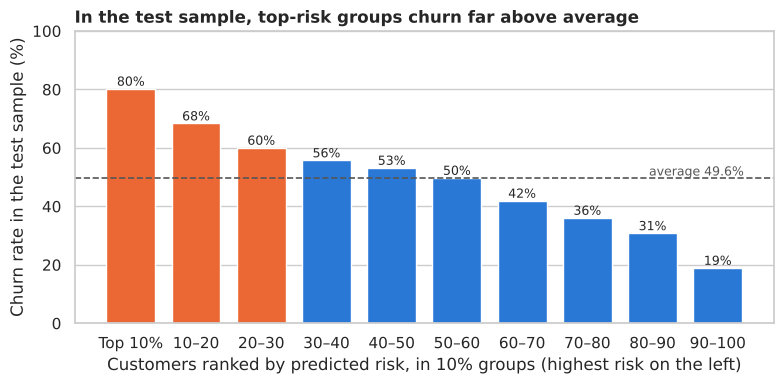

In [27]:
ranked = pd.DataFrame({"risk": best_proba, "churn": y_test.values}).sort_values("risk", ascending=False)
ranked["decile"] = np.arange(len(ranked)) * 10 // len(ranked) + 1      # 1 = highest-risk 10%

gains = ranked.groupby("decile").agg(customers=("churn", "size"), churners=("churn", "sum"),
                                     churn_rate=("churn", "mean"))
gains["cum_share_of_churners"] = gains["churners"].cumsum() / gains["churners"].sum()
gains["lift"] = gains["churn_rate"] / ranked["churn"].mean()
display(gains.style.format({"churn_rate": "{:.1%}", "cum_share_of_churners": "{:.1%}", "lift": "{:.2f}x"}))

fig, ax = plt.subplots(figsize=(8, 4))
colors = [COLOR_CHURN if d <= 3 else COLOR_STAY for d in gains.index]
ax.bar([f"Top {d*10}%" if d == 1 else f"{(d-1)*10}–{d*10}" for d in gains.index], gains["churn_rate"] * 100,
       color=colors, width=0.75)
ax.axhline(ranked["churn"].mean() * 100, ls="--", color="#555", lw=1.2)
ax.text(9.4, ranked["churn"].mean() * 100 + 1, f"average {ranked['churn'].mean():.1%}", ha="right", fontsize=9, color="#555")
for i, r in enumerate(gains["churn_rate"]):
    ax.text(i, r * 100 + 1, f"{r:.0%}", ha="center", fontsize=9)
ax.set_ylabel("Churn rate in the test sample (%)")
ax.set_xlabel("Customers ranked by predicted risk, in 10% groups (highest risk on the left)")
ax.set_ylim(0, 100)
ax.set_title("In the test sample, top-risk groups churn far above average", loc="left", fontweight="bold")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 6.6 Modeling summary

| | Result |
|---|---|
| Chosen model | LightGBM, chosen on cross-validation (ROC-AUC 0.698 ± 0.002) before the test set was used |
| ROC-AUC on 30,000 test customers | **0.699** |
| Accuracy / precision / recall / F1 (0.5 cut-off) | 0.640 / 0.635 / 0.643 / 0.639 |
| Other models (test) | Random Forest 0.682 · Logistic Regression 0.654 · Baseline (always "stay") 0.500 |
| Added features (6.4b) | +0.004 AUC; household & demographic fields add about +0.005 |

- An AUC of about 0.70 is moderate. That is normal for churn: the data cannot see things like a competitor's offer or a customer moving house.
- **The model is used to rank customers, not to give real-world probabilities.** Its scores come from a sample with 49.6% churn, so they are not calibrated to a live customer base.
- In the test sample, the riskiest 10% churn at 80% (1.6 times the sample average) and the riskiest 30% contain 42% of all churners; the safest 10% churn at 19%. These are **sample** rates; Section 7.4 translates the ranking to an assumed real-world churn rate.
- The model relies most on usage trend, phone age and tenure, the same patterns found in Section 3. This is predictive reliance, not proof of cause.

## 7. From model to business proposal

### 7.1 Market context: India
Company A is anonymous and its country is not given. I use the Indian mobile market as a **reference context**, not as Company A's own data. The figures come from public sources listed in the References; note that they come from different months.

| Fact | Figure | Source |
|---|---|---|
| Mobile subscribers (Aug 2026) | 1,293 million; Jio 39.3%, Airtel 38.0%, Vi 15.4%, BSNL 7.2% | TRAI via TelecomTalk [1] |
| Number-porting **requests** (May 2026) | 14.46 million in one month: 1.1% of the 1,277 M mobile base, or 1.26% excluding machine (M2M) connections. These are requests, not completed ports | TRAI via PIB [2a] and TelecomTalk [2] |
| Monthly revenue per user, Q1 FY27 | Airtel Rs 264 · Jio Rs 215.6 · Vi Rs 177 | TelecomTalk [3] |
| Postpaid growth | Airtel postpaid base of 30 million, a record +1 million in Q1 FY27 | TelecomTalk [4] |
| Smartphones bought on credit | 42% of sales expected in 2026 | Counterpoint [5] |
| Average smartphone EMI tenure | 10 months (Q2 2026) | Counterpoint [6] |
| Tariffs | Analysts expect a further 10–20% rise (an expectation, reported by a secondary summary) | Multibagg AI [7] |
| Cost of winning vs keeping a customer | HBR cites estimates of 5–25 times, depending on study and industry | Gallo, HBR (2014) [8] |

**What this means for Company A**
- Switching is common: roughly 1 in 80–90 Indian mobile users *asks* to port their number every month.
- Phones drive decisions: most smartphones are bought on EMI plans of about 10 months, the same point where churn jumps in Section 3.2. Company A's data is not from India, so this is a matching pattern, not proof.
- With tariffs going up, customers shop around more, and keeping existing customers matters even more.

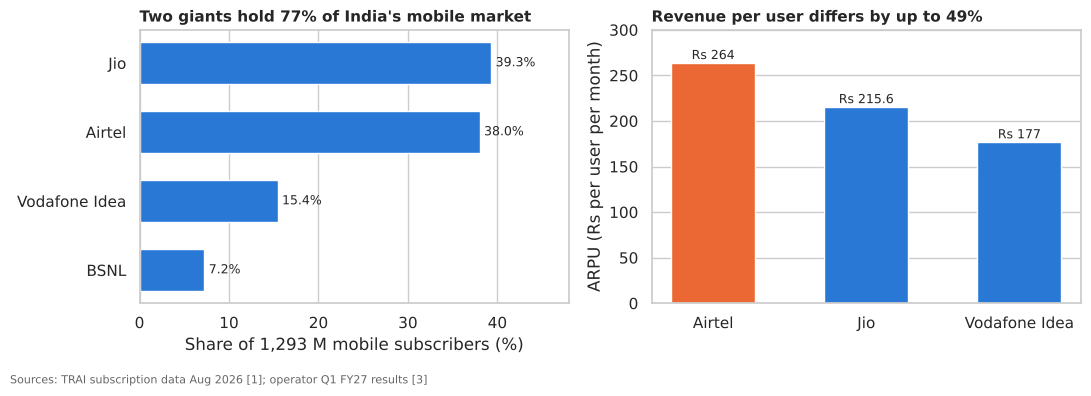

In [28]:
# Market-context charts (figures hard-coded from the cited sources above)
share = pd.Series({"Jio": 39.31, "Airtel": 38.01, "Vodafone Idea": 15.43, "BSNL": 7.24})
arpu = pd.Series({"Airtel": 264, "Jio": 215.6, "Vodafone Idea": 177})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].barh(share.index[::-1], share.values[::-1], color=COLOR_STAY, height=0.6)
for yv, v in enumerate(share.values[::-1]):
    axes[0].text(v + 0.5, yv, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_xlim(0, 48)
axes[0].set_xlabel("Share of 1,293 M mobile subscribers (%)")
axes[0].set_title("Two giants hold 77% of India's mobile market", loc="left", fontweight="bold", fontsize=11)
axes[0].grid(axis="y", visible=False)

axes[1].bar(arpu.index, arpu.values, color=[COLOR_CHURN, COLOR_STAY, COLOR_STAY], width=0.55)
for xv, v in enumerate(arpu.values):
    axes[1].text(xv, v + 4, f"Rs {v:g}", ha="center", fontsize=9)
axes[1].set_ylim(0, 300)
axes[1].set_ylabel("ARPU (Rs per user per month)")
axes[1].set_title("Revenue per user differs by up to 49%", loc="left", fontweight="bold", fontsize=11)
axes[1].grid(axis="x", visible=False)
fig.text(0.01, -0.03, "Sources: TRAI subscription data Aug 2026 [1]; operator Q1 FY27 results [3]", fontsize=8, color="#666")
plt.tight_layout()
plt.show()

### 7.2 Who is in the high-risk group?
Before choosing an offer, I check what the model's riskiest 10% of customers have in common.

,Top 10% risk,All customers
Handset older than 10 months,83%,60%
In contract-end window (months 10-14),46%,29%
Handset priced at $30 or less,38%,26%
Usage fell more than 20%,60%,32%
Median monthly revenue ($),$40,$48


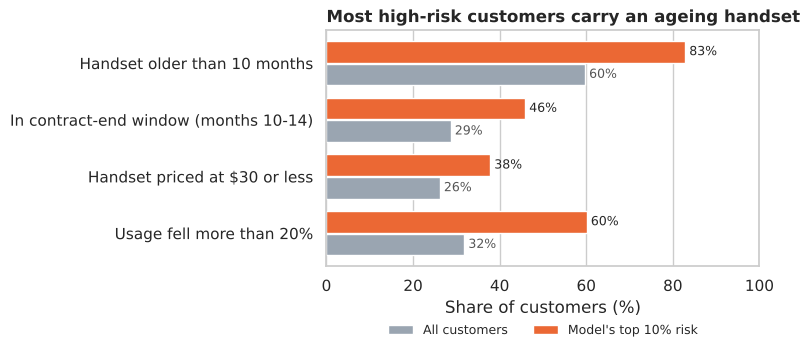

In [29]:
test_view = X_test.assign(risk=best_proba, churn=y_test.values).sort_values("risk", ascending=False)
n_top = int(len(test_view) * 0.10)
top10, everyone = test_view.head(n_top), test_view

profile = pd.DataFrame({
    "Top 10% risk": [ (top10["eq_months"] >= 10).mean(), top10["months"].between(10, 14).mean(),
                      (top10["hnd_price"] <= 30).mean(), (top10["usage_change_ratio"] < -0.2).mean(),
                      top10["rev_Mean"].median()],
    "All customers": [(everyone["eq_months"] >= 10).mean(), everyone["months"].between(10, 14).mean(),
                      (everyone["hnd_price"] <= 30).mean(), (everyone["usage_change_ratio"] < -0.2).mean(),
                      everyone["rev_Mean"].median()],
}, index=["Handset older than 10 months", "In contract-end window (months 10-14)",
          "Handset priced at $30 or less", "Usage fell more than 20%", "Median monthly revenue ($)"])

def fmt(v, row):
    return f"${v:.0f}" if "revenue" in row else f"{v:.0%}"
display(pd.DataFrame({c: [fmt(v, r) for r, v in profile[c].items()] for c in profile.columns},
                     index=profile.index))

shares = profile.iloc[:4]
fig, ax = plt.subplots(figsize=(8, 3.8))
yy = np.arange(len(shares))
ax.barh(yy + 0.2, shares["All customers"] * 100, height=0.38, color="#9aa5b1", label="All customers")
ax.barh(yy - 0.2, shares["Top 10% risk"] * 100, height=0.38, color=COLOR_CHURN, label="Model's top 10% risk")
for i, (a, b) in enumerate(zip(shares["Top 10% risk"], shares["All customers"])):
    ax.text(a * 100 + 1, i - 0.2, f"{a:.0%}", va="center", fontsize=9)
    ax.text(b * 100 + 1, i + 0.2, f"{b:.0%}", va="center", fontsize=9, color="#555")
ax.set_yticks(yy, shares.index)
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of customers (%)")
ax.set_title("Most high-risk customers carry an ageing handset", loc="left", fontweight="bold")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, fontsize=9, frameon=False)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

### 7.3 The proposal: Smart Upgrade (an intervention to test)
Each month:
1. **Score** every customer with the churn model.
2. **Select** the riskiest group (its size is chosen in 7.4), starting with customers in months 9–10 of tenure. This timing is itself a hypothesis: it comes from the churn peak in month 11, and the pilot should test it. Customers already contacted in the past 12 months are skipped.
3. **Offer** a new phone on EMI with a small subsidy, tied to a 12-month renewal.
4. **Measure** the effect against a random control group that does not get the offer (Section 7.8).

The data shows that churn is *associated* with tenure and phone age; it does not prove that an upgrade will stop customers leaving. Smart Upgrade is therefore proposed as a pilot, not as a proven fix.

### 7.4 Business case

**How the sample is translated to the real world.** The data has about 50% churn. For the business case I *assume* a monthly churn rate of 1.1%, informed by India's porting requests (Section 7.1). This is a scenario assumption, not a measured churn rate, and it is tested in 7.5. The model is used **only to rank** customers; its raw probabilities reflect the 50/50 sample and are not real-world churn probabilities. I keep its ranking ability (its true- and false-positive rates at a given score threshold) and recalculate how many real churners the targeted group would contain at the 1.1% rate. This rests on four assumptions:

| # | Assumption | Why it may not hold |
|---|---|---|
| A1 | The 50/50 sample was built by balancing the two classes, and customers *within* each class are representative | If the sample was selected in another way, rates in the risk groups may differ in practice |
| A2 | The churn window (31–60 days after observation) is roughly one month, comparable to a monthly churn rate | The window may not line up exactly with a calendar month |
| A3 | A monthly churn rate of about 1.1% | Porting requests are not completed ports, the base includes M2M (1.26% without it), and some churn happens without porting |
| A5 | Money in the data and the costs below share one currency unit (shown as \$) | The data dictionary does not state the currency |
| A4 | Company A behaves like an Indian operator | The dataset is not from India; currency and pricing differ |

**How the target group size is chosen without peeking at the test set.** The threshold is picked using *out-of-fold* predictions on the training data (5-fold cross-validation), maximising the base scenario's profit. That fixed threshold is then applied **once** to the 30,000 test customers to report the results.

**Scenarios.** The offer renews the contract for 12 months, so the months a saved customer stays are set consistently with that:

| Scenario | Churners saved by the offer | Months a saved customer stays | Stayers who also take the subsidy |
|---|---|---|---|
| Conservative | 15% | 12 (the renewal only) | 15% |
| Base | 25% | 18 (12-month renewal + about 6 months on average after it) | 10% |
| Optimistic | 30% | 24 | 10% |

**What the numbers mean:** "net per cohort" is the *expected net lifetime contribution* of one monthly campaign (value earned over the months a saved customer stays, minus campaign costs). "12 cohorts" adds twelve such campaigns. It is a scenario estimate, not a guaranteed profit or a yearly cash flow.

Shared assumptions: \$40 monthly revenue (median of the top-risk group, from the data), 50% contribution margin, \$2 to contact a customer, \$30 subsidy per accepted upgrade. A churner who accepts is counted as saved, because accepting means renewing the contract; churners who decline cost only the contact.

In [30]:
SHARED = dict(base_customers=1_000_000,   # results scaled to 1 million subscribers
              monthly_churn_rate=0.011,  # A3: ~1.1% per month (14.46 M porting requests / 1,277 M users, TRAI May 2026)
              monthly_revenue=40.0,      # median monthly revenue of the model's top-risk group ($)
              margin=0.50,               # ASSUMPTION: contribution margin
              contact_cost=2.0,          # ASSUMPTION: cost to contact one customer ($)
              subsidy=30.0)              # ASSUMPTION: subsidy per accepted upgrade ($)
SCENARIOS = {
    "Conservative": dict(save_rate=0.15, months_retained=12, uptake_non_churners=0.15),
    "Base":         dict(save_rate=0.25, months_retained=18, uptake_non_churners=0.10),
    "Optimistic":   dict(save_rate=0.30, months_retained=24, uptake_non_churners=0.10),
}
pd.DataFrame(SCENARIOS).T

,save_rate,months_retained,uptake_non_churners
Conservative,0.15,12.0,0.15
Base,0.25,18.0,0.10
Optimistic,0.30,24.0,0.10


In [31]:
from sklearn.model_selection import cross_val_predict

def rates_at(scores, labels, threshold):
    """True-positive and false-positive rate when everyone scoring >= threshold is targeted."""
    labels = np.asarray(labels); chosen = scores >= threshold
    return (chosen & (labels == 1)).sum() / (labels == 1).sum(), (chosen & (labels == 0)).sum() / (labels == 0).sum()

def campaign(tpr, fpr, scenario, s=SHARED):
    """Expected result of ONE monthly campaign, re-weighted to the real churn rate (assumptions A1-A3)."""
    p, N = s["monthly_churn_rate"], s["base_customers"]
    churners = N * p * tpr                      # real churners inside the targeted group
    stayers = N * (1 - p) * fpr                 # targeted customers who would have stayed anyway
    targeted = churners + stayers
    saved = churners * scenario["save_rate"]
    value = saved * s["monthly_revenue"] * s["margin"] * scenario["months_retained"]
    cost = targeted * s["contact_cost"] + (saved + stayers * scenario["uptake_non_churners"]) * s["subsidy"]
    return dict(targeted=targeted, share_targeted=targeted / N, churners_in_group=churners,
                precision=churners / targeted if targeted else np.nan, saved=saved,
                value=value, cost=cost, net=value - cost)

# Step 1 - out-of-fold scores on the TRAINING set (each customer scored by a model that did not see it)
oof_proba = cross_val_predict(LGBMClassifier(**models["LightGBM"].get_params()), X_train_lgb, y_train,
                              cv=cv, method="predict_proba")[:, 1]
print(f"Out-of-fold ROC-AUC on the training set: {roc_auc_score(y_train, oof_proba):.3f}")

# Step 2 - choose the score threshold that maximises the BASE scenario on those out-of-fold scores
thresholds = np.quantile(oof_proba, np.linspace(0.5, 0.999, 400))
oof_curve = pd.DataFrame([{**campaign(*rates_at(oof_proba, y_train, t), SCENARIOS["Base"]), "threshold": t}
                          for t in thresholds])
chosen = oof_curve.loc[oof_curve["net"].idxmax()]
THRESHOLD = chosen["threshold"]
print(f"Chosen on training data: score >= {THRESHOLD:.3f}  ->  about {chosen['share_targeted']:.1%} of customers per month")

# Step 3 - apply that fixed threshold ONCE to the untouched test set
tpr_test, fpr_test = rates_at(best_proba, y_test, THRESHOLD)
in_slice = best_proba >= THRESHOLD
print(f"Test set: {in_slice.sum():,} of 30,000 sample customers pass the threshold; "
      f"{y_test.values[in_slice].mean():.0%} of them churned (sample rate, not a real-world rate)")

results_test = pd.DataFrame({name: campaign(tpr_test, fpr_test, sc) for name, sc in SCENARIOS.items()}).T
results_test["net per year"] = results_test["net"] * 12
# "net" = expected net lifetime contribution of ONE monthly campaign cohort; "net per year" = 12 such cohorts.
display(results_test[["targeted", "share_targeted", "churners_in_group", "precision", "saved", "value", "cost",
                      "net", "net per year"]].rename(columns={"net": "net per cohort", "net per year": "12 cohorts"}).style.format(
    {"targeted": "{:,.0f}", "share_targeted": "{:.2%}", "churners_in_group": "{:,.0f}", "precision": "{:.1%}",
     "saved": "{:,.0f}", "value": "${:,.0f}", "cost": "${:,.0f}", "net per cohort": "${:,.0f}", "12 cohorts": "${:,.0f}"}))

# Step 4 - sampling uncertainty of the base result (bootstrap of the test set; does NOT cover assumption risk)
rng = np.random.default_rng(RANDOM_STATE)
yt, boot = y_test.values, []
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    boot.append(campaign(*rates_at(best_proba[idx], yt[idx], THRESHOLD), SCENARIOS["Base"])["net"] * 12)
lo, hi = np.percentile(boot, [5, 95])
print(f"Base scenario, expected net contribution of 12 monthly cohorts: ${results_test.loc['Base', 'net per year']:,.0f} "
      f"(90% bootstrap interval ${lo:,.0f} to ${hi:,.0f})")

# Step 5 - reasonable alternatives (group sizes also fixed on training data, evaluated on test)
alt_rows = []
for target_share in [0.005, 0.01, 0.02, 0.05]:
    t = oof_curve.iloc[(oof_curve["share_targeted"] - target_share).abs().idxmin()]["threshold"]
    tp, fp = rates_at(best_proba, y_test, t)
    alt_rows.append({"policy": f"Riskiest ~{target_share:.1%}",
                     **{name: campaign(tp, fp, sc)["net"] * 12 for name, sc in SCENARIOS.items()}})
alt_rows.append({"policy": "Chosen threshold", **results_test["net per year"].to_dict()})
alt_rows.append({"policy": "Everyone (no model)", **{name: campaign(1.0, 1.0, sc)["net"] * 12
                                                    for name, sc in SCENARIOS.items()}})
alternatives = pd.DataFrame(alt_rows).set_index("policy")
alternatives.style.format("${:,.0f}")

Out-of-fold ROC-AUC on the training set: 0.698
Chosen on training data: score >= 0.846  ->  about 0.7% of customers per month
Test set: 905 of 30,000 sample customers pass the threshold; 89% of them churned (sample rate, not a real-world rate)


,targeted,share_targeted,churners_in_group,precision,saved,value,cost,net per cohort,12 cohorts
Conservative,"6,938",0.69%,598,8.6%,90,"$21,519","$45,096","$-23,577","$-282,928"
Base,"6,938",0.69%,598,8.6%,149,"$53,798","$37,379","$16,418","$197,020"
Optimistic,"6,938",0.69%,598,8.6%,179,"$86,077","$38,276","$47,800","$573,605"


Base scenario, expected net contribution of 12 monthly cohorts: $197,020 (90% bootstrap interval $123,627 to $268,552)


,Conservative,Base,Optimistic
policy,,,
Riskiest ~0.5%,"$-212,807","$158,585","$451,277"
Riskiest ~1.0%,"$-410,177","$189,458","$648,071"
Riskiest ~2.0%,"$-1,010,470","$29,962","$763,091"
Riskiest ~5.0%,"$-2,923,383","$-844,157","$431,478"
Chosen threshold,"$-282,928","$197,020","$573,605"
Everyone (no model),"$-73,248,000","$-48,714,000","$-41,784,000"


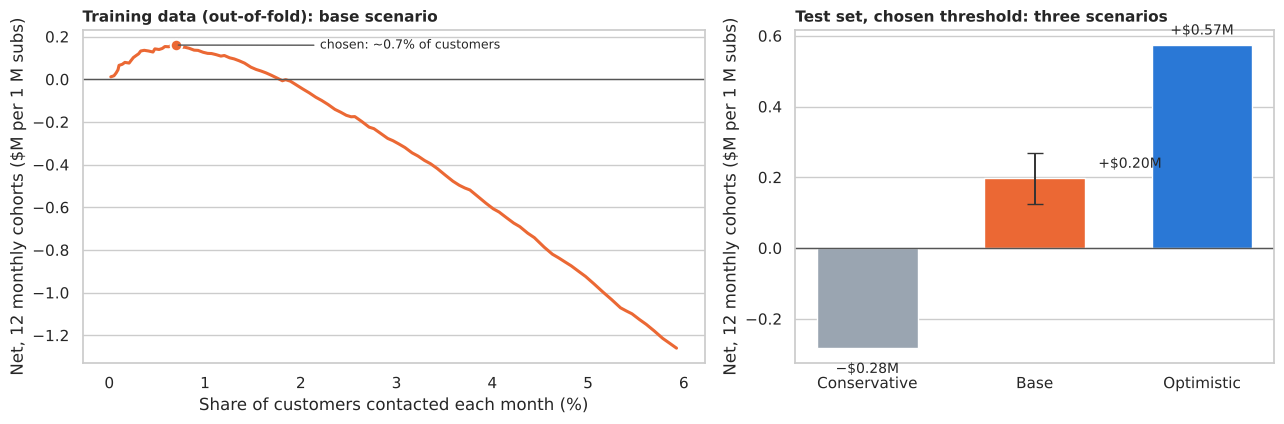

In [32]:
view = oof_curve[oof_curve["share_targeted"] <= 0.06].sort_values("share_targeted")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
ax.plot(view["share_targeted"] * 100, view["net"] * 12 / 1e6, color=COLOR_CHURN, lw=2.2)
ax.axhline(0, color="#555", lw=1)
ax.scatter([chosen["share_targeted"] * 100], [chosen["net"] * 12 / 1e6], s=70, color=COLOR_CHURN,
           edgecolor="white", linewidth=1.5, zorder=3)
ax.annotate(f"chosen: ~{chosen['share_targeted']:.1%} of customers", xy=(chosen["share_targeted"] * 100, chosen["net"] * 12 / 1e6),
            xytext=(2.2, chosen["net"] * 12 / 1e6 * 0.9), fontsize=9, arrowprops=dict(arrowstyle="-", color="#555"))
ax.set_xlabel("Share of customers contacted each month (%)")
ax.set_ylabel("Net, 12 monthly cohorts ($M per 1 M subs)")
ax.set_title("Training data (out-of-fold): base scenario", loc="left", fontweight="bold", fontsize=11)
ax.grid(axis="x", visible=False)

ax = axes[1]
vals = results_test["net per year"] / 1e6
bars = ax.bar(vals.index, vals.values, color=["#9aa5b1", COLOR_CHURN, COLOR_STAY], width=0.6)
ax.errorbar([1], [vals["Base"]], yerr=[[vals["Base"] - lo / 1e6], [hi / 1e6 - vals["Base"]]],
            fmt="none", ecolor="#333", capsize=6, lw=1.4)
ax.axhline(0, color="#555", lw=1)
for i, v in enumerate(vals.values):
    label = f"{'+' if v >= 0 else '−'}${abs(v):.2f}M"
    ax.text(i + (0.38 if i == 1 else 0), v + (0.03 if v >= 0 else -0.07), label, ha="left" if i == 1 else "center", fontsize=10)
ax.set_ylabel("Net, 12 monthly cohorts ($M per 1 M subs)")
ax.set_title("Test set, chosen threshold: three scenarios", loc="left", fontweight="bold", fontsize=11)
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

### 7.5 Sensitivity analysis
Keeping the chosen threshold fixed, I vary the two most uncertain assumptions: how many churners the offer saves, and how long a saved customer stays. This shows the conditions the pilot must confirm before a roll-out. A one-way check of the other assumptions follows.

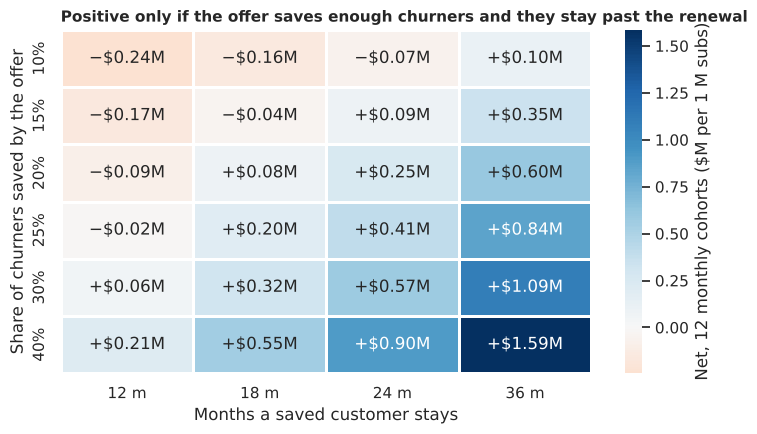

In [33]:
save_rates = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40]
horizons = [12, 18, 24, 36]
sens = pd.DataFrame(index=[f"{s:.0%}" for s in save_rates], columns=[f"{h} m" for h in horizons], dtype=float)
for s in save_rates:
    for h in horizons:
        sc = {**SCENARIOS["Base"], "save_rate": s, "months_retained": h}
        sens.loc[f"{s:.0%}", f"{h} m"] = campaign(tpr_test, fpr_test, sc)["net"] * 12 / 1e6

fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(sens, annot=sens.map(lambda v: f"{'+' if v >= 0 else '−'}${abs(v):.2f}M"), fmt="", cmap="RdBu", center=0, linewidths=2,
            linecolor="white", cbar_kws={"label": "Net, 12 monthly cohorts ($M per 1 M subs)"}, ax=ax)
ax.set_xlabel("Months a saved customer stays")
ax.set_ylabel("Share of churners saved by the offer")
ax.set_title("Positive only if the offer saves enough churners and they stay past the renewal",
             loc="left", fontweight="bold", fontsize=11)
plt.tight_layout()
plt.show()

**One-way sensitivity.** Each remaining assumption is moved on its own, everything else at the base case, with the same fixed threshold.

In [34]:
def base_with(**changes):
    shared = {**SHARED, **{k: v for k, v in changes.items() if k in SHARED}}
    scen = {**SCENARIOS["Base"], **{k: v for k, v in changes.items() if k in SCENARIOS["Base"]}}
    return campaign(tpr_test, fpr_test, scen, s=shared)["net"] * 12

tests = [("Monthly churn rate", "monthly_churn_rate", 0.008, 0.015),
         ("Contribution margin", "margin", 0.40, 0.60),
         ("Monthly revenue", "monthly_revenue", 30.0, 50.0),
         ("Contact cost", "contact_cost", 4.0, 1.0),
         ("Subsidy per upgrade", "subsidy", 50.0, 20.0),
         ("Stayers taking the subsidy", "uptake_non_churners", 0.20, 0.05)]
rows = [{"assumption": name, "low value": low, "net if low": base_with(**{key: low}),
         "high value": high, "net if high": base_with(**{key: high})} for name, key, low, high in tests]
oneway = pd.DataFrame(rows).set_index("assumption")
print(f"Base case: ${base_with():,.0f}")
oneway.style.format({"low value": "{:g}", "high value": "{:g}", "net if low": "${:,.0f}", "net if high": "${:,.0f}"})

Base case: $197,020


,low value,net if low,high value,net if high
assumption,,,,
Monthly churn rate,0.008,"$38,385",0.015,"$408,533"
Contribution margin,0.4,"$67,906",0.6,"$326,135"
Monthly revenue,30,"$35,627",50,"$358,414"
Contact cost,4,"$30,510",1,"$280,275"
Subsidy per upgrade,50,"$8,991",20,"$291,035"
Stayers taking the subsidy,0.2,"$-31,226",0.05,"$311,143"


### 7.6 Risks and how to handle them

| Risk | Evidence | What I propose |
|---|---|---|
| The savings depend on unproven assumptions (save rate, how long customers stay) | Sections 7.4–7.5: the conservative scenario loses money | Treat the figures as conditional estimates; decide on roll-out only after the pilot |
| Contacting customers can push some of them to leave | In a telecom field experiment, proactive plan advice raised churn from 6% to 10% [9] | Pilot with a random control group; avoid messages that point to cheaper plans |
| The riskiest customers are not always the easiest to persuade | Ascarza (2018): targeting by expected response beats targeting by risk [10] | After the pilot, use its treatment and control data to build an uplift model |
| Phone age and tenure are linked to churn, but the cause is not proven | Section 3.3 | The pilot measures the real effect of the offer |
| The sample may not represent the target market | Assumptions A1–A4 (Section 7.4) | Re-check rates on live Company A data before scaling |
| Household fields (income, marital status…) may raise fairness concerns | Ethnicity is excluded; Section 6.4b shows what the other personal fields add | Consider dropping them in production and check results across customer groups |
| Model accuracy is moderate (AUC 0.70) and may drift over time | Section 6 (random split, not a time-based test) | Monitor performance each month and retrain when it drops |

### 7.7 Business case summary

Expected net lifetime contribution, per 1 million subscribers, adding up **12 monthly campaign cohorts**. The threshold was chosen on training data and evaluated once on the test set. All money is in the dataset's units (shown as \$).

| | Conservative | **Base** | Optimistic | Same offer to everyone (base) |
|---|---|---|---|---|
| Customers contacted per month | ~6,900 (0.7%) | ~6,900 (0.7%) | ~6,900 (0.7%) | 1,000,000 |
| Expected churners among them (at 1.1% assumed churn) | 8.6% | 8.6% | 8.6% | 1.1% |
| Customers saved per month | ~90 | ~150 | ~180 | ~2,750 |
| **Net, 12 monthly cohorts** | **−\$0.28M** | **+\$0.20M** | **+\$0.57M** | **−\$48.7M** |

- **Base case: about +\$0.2M per million subscribers for 12 monthly cohorts** (90% bootstrap interval \$0.12M to \$0.27M). The interval only reflects sampling noise in the test set, not uncertainty in the assumptions.
- **It is a scenario estimate, not a guaranteed profit or yearly cash flow.** The value of a saved customer is earned over the months they stay, and the twelve cohorts must reach different customers (anyone contacted in the past 12 months is skipped).
- **The result depends on the assumptions.** The conservative case loses money, and the one-way check shows the base case turns negative if 20% of non-churners take the subsidy. A higher churn rate (for example 1.26%, excluding M2M connections) improves the result.
- **The model is what makes a profit possible:** the same offer sent to everyone loses tens of millions, because almost nobody who receives it was going to leave.
- **Stay small:** targeting the riskiest 0.5–1% gives similar results (+\$0.16M to +\$0.19M in the base case); beyond about 2% the base case turns negative.

### 7.8 Pilot design: what it must measure
The churn model predicts *who is likely to leave*. It cannot tell us *who the offer actually keeps*; only a comparison with a random control group can.

**Set-up (3 months):** each month, take the customers above the chosen threshold and split them at random: half get the offer (treatment), half do not (control).

| What to measure | How |
|---|---|
| Extra customers kept by the offer | Churn rate in control minus churn rate in treatment |
| Offer uptake | Share of the treatment group that accepts, split into would-be churners and stayers where possible |
| Cost per customer kept | Total campaign cost ÷ extra customers kept |
| Net value of the campaign | Value of extra customers kept − total cost |
| Side effects | Complaints, and any rise in churn in the treatment group |

**Decision rule:** scale up only if the measured save rate and retention period put the result in the positive area of Section 7.5. An uplift model is only built after this, from the pilot's treatment and control data.

## 8. Conclusion and next steps

1. **What the data shows:** churn rises sharply around month 11 of tenure (65% in the sample vs 29% in month 9) and is higher for customers whose phone is older than about 10 months. These are associations. They would fit a contract-end and phone-ageing story, but the data does not confirm contracts or causes. Dropped-call and care-call *counts* show no link to churn here, which does not mean network quality is unimportant.
2. **Model:** LightGBM, chosen on cross-validation and tested once: ROC-AUC 0.699 on 30,000 unseen customers (accuracy 0.640), ahead of Random Forest (0.682), Logistic Regression (0.654) and a baseline (0.500). It is used to rank customers. In the test sample its riskiest 10% churn at 80%, and 83% of that group has a phone older than 10 months.
3. **Proposal (Smart Upgrade), to be piloted:** each month, offer the riskiest ~0.7% of customers a subsidised phone upgrade on EMI with a 12-month renewal, ideally in months 9–10 (the timing is itself a hypothesis).
4. **Expected value, under stated assumptions:** about +\$0.2M per million subscribers for 12 monthly cohorts in the base case, ranging from −\$0.28M (conservative) to +\$0.57M (optimistic). Sending the same offer to everyone would lose heavily.
5. **Next steps:** a 3-month pilot with a random control group (Section 7.8); scale up only if the measured results fall in the positive area of Section 7.5. Then build an uplift model from the pilot data, consider dropping household fields, and monitor the model monthly, retraining when performance drops.

## References

1. TelecomTalk (28 Sep 2026). *India wireless subscriber base, August 2026 (TRAI data).* https://telecomtalk.info/india-wireless-telecom-subscriber-base-130billion-august2026/1012285/
2a. Press Information Bureau, Ministry of Communications (25 Jun 2026). *Highlights of Telecom Subscription Data at the end of May 2026.* https://www.pib.gov.in/PressReleasePage.aspx?PRID=2277922
2. TelecomTalk (28 Jun 2026). *UP East, UP West, Bihar lead mobile number porting requests in May 2026: TRAI.* https://telecomtalk.info/upeast-upwest-bihar-mnp-requests-may2026-trai/1009192/
3. TelecomTalk (13 Aug 2026). *Airtel, Reliance Jio, Vodafone Idea ARPU in Q1 FY27.* https://telecomtalk.info/airtel-reliance-jio-vodafone-idea-arpu-q1fy27/1010651/
4. TelecomTalk (4 Aug 2026). *Bharti Airtel ARPU Rs 264, postpaid base 30 million in Q1 FY27.* https://telecomtalk.info/bhartiairtel-arpu-rs264-postpaid-base-30million-q1fy27/1010410/
5. Counterpoint Research (3 Jul 2026). *Rising prices to push financing to 42% of India's smartphone sales in 2026.* https://counterpointresearch.com/en/insights/rising-prices-to-push-financing-to-42-percent-of-indias-smartphone-sales-in-2026
6. Counterpoint Research (10 Aug 2026). *Average smartphone financing tenure reaches 10 months in Q2 2026.* https://counterpointresearch.com/en/insights/average-smartphone-financing-tenure-reaches-10-months-in-q2-2026
7. Multibagg AI (22 Apr 2026). *Indian telecom tariff hike 2026: what analysts expect.* https://www.multibagg.ai/market-pulse/articles/indian-telecom-tariff-hike-2026-prices-cmo9oadyzug1hph0jbgloei2r
8. Gallo, A. (2014). *The Value of Keeping the Right Customers.* Harvard Business Review. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
9. Knowledge at Wharton (2015). *Why retention plans don't work* (Ascarza, Iyengar & Schleicher field experiment). https://knowledge.wharton.upenn.edu/article/why-retention-plans-dont-work/
10. American Marketing Association (2019). *Ascarza's "Retention Futility: Targeting High-Risk Customers Might Be Ineffective" (JMR, 2018) wins award.* https://www.ama.org/2019/04/24/escarzas-retention-futility-targeting-high-risk-customers-might-be-ineffective-wins-2018-award/
11. GCI World 2026 September, Final Assignment materials: README, Dataset Overview and `tutorial.ipynb` (Matsuo-Iwasawa Lab, University of Tokyo).
12. Generative AI assistance (Claude): Generative AI assistance: Claude (Anthropic) and ChatGPT (OpenAI, https://chatgpt.com/share/6ad5a390-b994-83e8-8c19-6d72c752c123) were used for coding support, analysis review and editing. All results were run, checked and interpreted by the author.